In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


In [2]:
arquivo = files.upload()

Saving turtle.jpg to turtle.jpg


array([[127, 128, 127, ..., 135, 134, 135],
       [125, 125, 125, ..., 136, 134, 134],
       [123, 123, 124, ..., 137, 134, 134],
       ...,
       [132, 127, 125, ..., 137, 131, 128],
       [130, 131, 129, ..., 136, 133, 133],
       [136, 141, 137, ..., 136, 135, 136]], dtype=uint8)
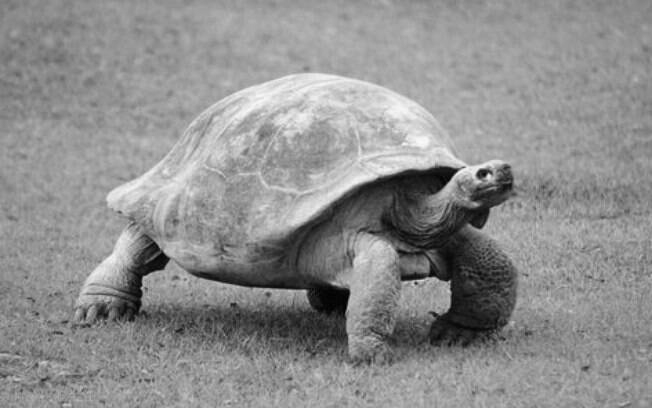

In [3]:
img_bgr = cv2.imread('turtle.jpg')
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_RGB2GRAY)
img_gray

In [7]:
altura = img_gray.shape[0]
largura = img_gray.shape[1]

print(altura, largura)

408 652


# 1. Translação de exclusão

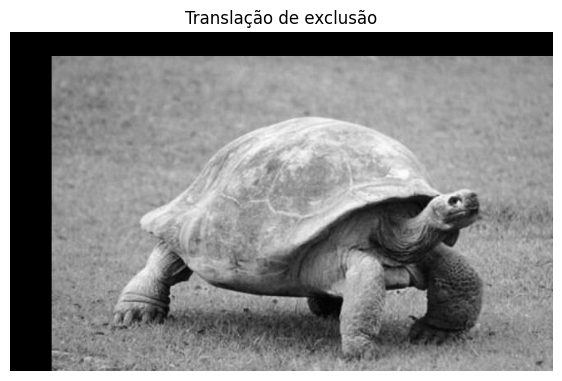

In [8]:
dx = 50
dy = 30

transladada = np.zeros((altura, largura), dtype=np.uint8)

for x in range(largura):
  for y in range(altura):

    novo_x = x + dx
    novo_y = y + dy

    if 0 <= novo_x and novo_x < largura:
      if 0 <= novo_y and novo_y < altura:
        transladada[novo_y, novo_x] = img_gray[y,x]

plt.figure(figsize=(7,5))
plt.imshow(transladada, cmap='gray')
plt.title('Translação de Exclusão')
plt.axis('off')
plt.show()


# 2. Translação de wrap-around

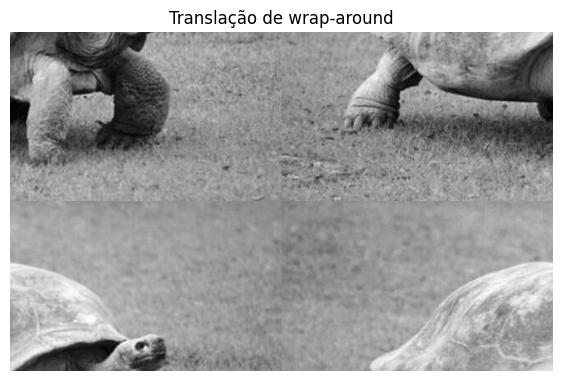

In [11]:
dx = 326
dy = 204

transladada = np.zeros((altura, largura), dtype=np.uint8)

for x in range(largura):
  for y in range(altura):

    novo_x = (x + dx) % largura
    novo_y = (y + dy) % altura

    transladada[novo_y, novo_x] = img_gray[y,x]

plt.figure(figsize=(7,5))
plt.imshow(transladada, cmap='gray')
plt.title('Translação de wrap-around')
plt.axis('off')
plt.show()

# 3. Escalamento

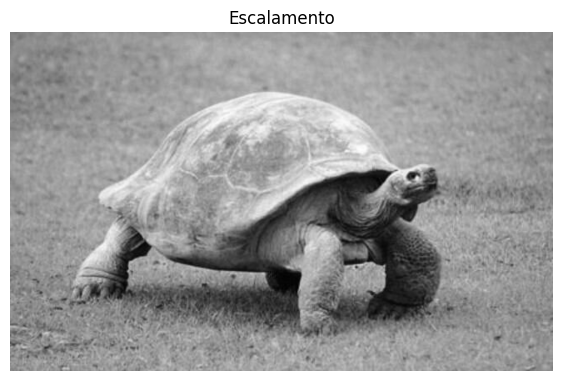

In [12]:
sx = 3.0
sy = 3.0

nova_largura = int(largura * sx)
nova_altura = int(altura * sy)

escalada = np.zeros((nova_altura, nova_largura), dtype=np.uint8)

for x in range(nova_largura):
  for y in range(nova_altura):

    novo_x = int(x / sx)
    novo_y = int(y / sy)

    escalada[y,x] = img_gray[novo_y, novo_x]

plt.figure(figsize=(7,5))
plt.imsave('turtle_3_0.png', escalada)
plt.imshow(escalada, cmap='gray')
plt.title('Escalamento')
plt.axis('off')
plt.show()

# 4. Espelhamento

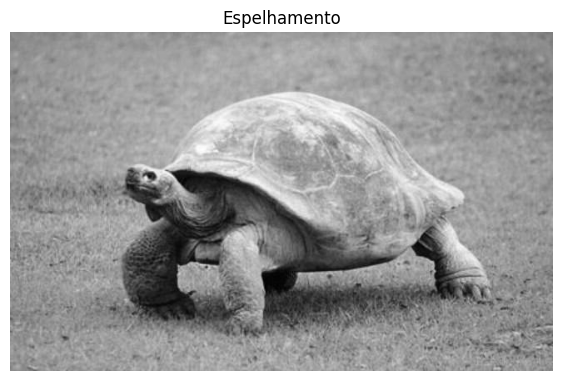

In [13]:
espelhada_h = np.zeros((altura, largura), dtype=np.uint8)
espelhada_v = np.zeros((altura, largura), dtype=np.uint)

for x in range(largura):
  for y in range(altura):

    novo_x = largura - x - 1
    novo_y = altura - y - 1

    espelhada_h[y, novo_x] = img_gray[y, x]
    espelhada_v[novo_y, x] = img_gray[y, x]

plt.figure(figsize=(7,5))
plt.imshow(espelhada_h, cmap='gray')
plt.title('Espelhamento')
plt.axis('off')
plt.show()

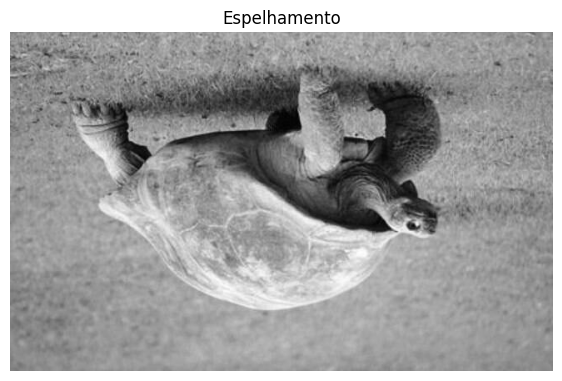

In [14]:
plt.figure(figsize=(7,5))
plt.imshow(espelhada_v, cmap='gray')
plt.title('Espelhamento')
plt.axis('off')
plt.show()